# 二元分类模型验证

本notebook用于训练和评估用于火灾预测的二元分类模型。

In [1]:
import os
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))

import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')

## 1. 数据准备

In [2]:
print("\n正在准备数据...")
merged_data, humid_cols = data_processor.prepare_weather_fire_data(
    data_type='binary',  # 指定二元分类
    weather_types=['humid']  # 只使用湿度数据
)



正在准备数据...

合并后的数据信息:
数据形状: (1625, 30)
选择的天气类型: ['humid']


## 2. 数据集划分

In [3]:
from data_processor import split_dataset

(X_train, y_train), (X_val, y_val), (X_test, y_test) = data_processor.split_dataset(
    merged_data=merged_data,
    feature_columns=humid_cols,  # 只使用湿度特征
    target_column='fire_binary'
)


数据集划分情况:
训练集大小: 975 (60.00%)
验证集大小: 325 (20.00%)
测试集大小: 325 (20.00%)

训练集类别分布:
fire_binary
1    76.512821
0    23.487179
Name: proportion, dtype: float64

验证集类别分布:
fire_binary
1    76.0
0    24.0
Name: proportion, dtype: float64

测试集类别分布:
fire_binary
1    76.307692
0    23.692308
Name: proportion, dtype: float64


## 3. 特征预处理

In [5]:
from data_processor import preprocess_features

print("\n正在预处理特征...")
X_train_processed, X_val_processed, X_test_processed = preprocess_features(X_train, X_val, X_test)


正在预处理特征...

数据预处理结果:
训练集形状: (975, 29)
验证集形状: (325, 29)
测试集形状: (325, 29)

处理后的缺失值检查:
训练集缺失值: 0
验证集缺失值: 0
测试集缺失值: 0


## 4. 模型训练和评估函数定义

In [6]:
def train_and_evaluate_models(X_train, X_val, y_train, y_val):
    """从model_trainer.py复制的函数内容"""
    # 1. 逻辑回归
    lr_model = LogisticRegression(random_state=42, max_iter=1000)
    lr_model.fit(X_train, y_train)
    lr_pred = lr_model.predict(X_val)
    lr_prob = lr_model.predict_proba(X_val)[:, 1]
    
    # 2. 随机森林
    rf_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_val)
    rf_prob = rf_model.predict_proba(X_val)[:, 1]
    
    # 评估结果
    models = {
        'Logistic Regression': (lr_pred, lr_prob, lr_model),
        'Random Forest': (rf_pred, rf_prob, rf_model)
    }
    
    # 绘制ROC曲线比较
    plt.figure(figsize=(10, 8))
    colors = ['blue', 'red']
    for (name, (pred, prob, model)), color in zip(models.items(), colors):
        fpr, tpr, _ = roc_curve(y_val, prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2,
                label=f'{name} (AUC = {roc_auc:.3f})')
    
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves Comparison')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    
    # 打印评估结果和绘制可视化
    for name, (pred, prob, model) in models.items():
        print(f"\n{name} 评估结果:")
        print("\n分类报告:")
        print(classification_report(y_val, pred))
        print("\nROC-AUC得分:", roc_auc_score(y_val, prob))
        
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_val, pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f'{name} Confusion Matrix')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.show()
        
        plt.figure(figsize=(10, 6))
        if name == 'Random Forest':
            feature_importance = pd.DataFrame({
                'feature': X_train.columns,
                'importance': model.feature_importances_
            }).sort_values('importance', ascending=False)
            
            sns.barplot(data=feature_importance.head(10), x='importance', y='feature')
            plt.title('Random Forest Feature Importance (Top 10)')
            plt.xlabel('Importance Score')
        else:
            feature_weights = pd.DataFrame({
                'feature': X_train.columns,
                'coefficient': np.abs(model.coef_[0])
            }).sort_values('coefficient', ascending=False)
            
            sns.barplot(data=feature_weights.head(10), x='coefficient', y='feature')
            plt.title('Logistic Regression Absolute Coefficients (Top 10)')
            plt.xlabel('|Coefficient|')
        
        plt.ylabel('Feature')
        plt.tight_layout()
        plt.show()
    
    return models

## 5. 执行模型训练和评估


开始训练和评估模型...


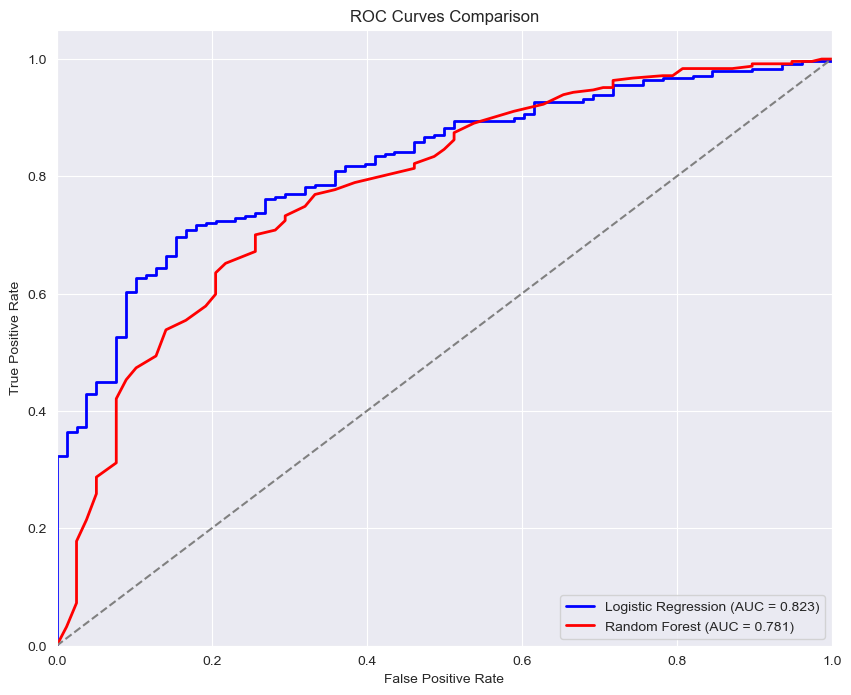


Logistic Regression 评估结果:

分类报告:
              precision    recall  f1-score   support

           0       0.62      0.37      0.46        78
           1       0.82      0.93      0.87       247

    accuracy                           0.79       325
   macro avg       0.72      0.65      0.67       325
weighted avg       0.77      0.79      0.77       325


ROC-AUC得分: 0.8230042562026368


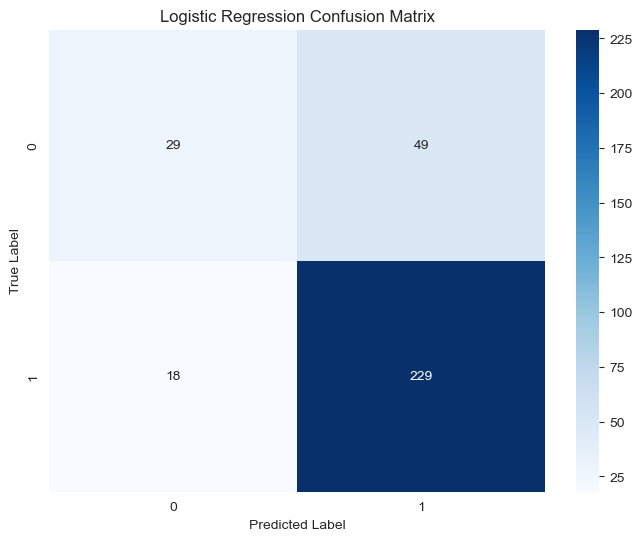

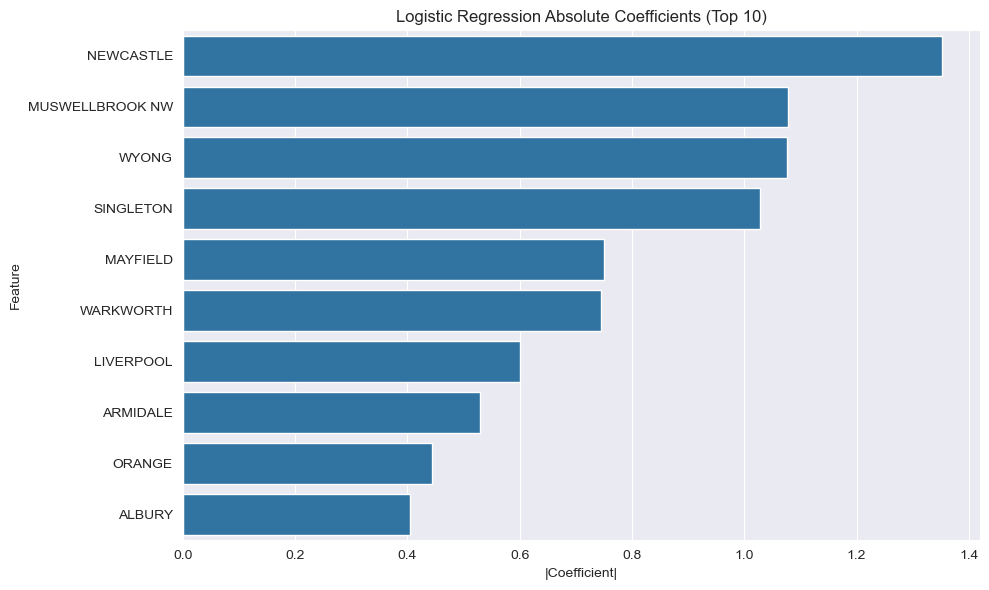


Random Forest 评估结果:

分类报告:
              precision    recall  f1-score   support

           0       0.71      0.26      0.38        78
           1       0.80      0.97      0.88       247

    accuracy                           0.80       325
   macro avg       0.76      0.61      0.63       325
weighted avg       0.78      0.80      0.76       325


ROC-AUC得分: 0.7810650887573963


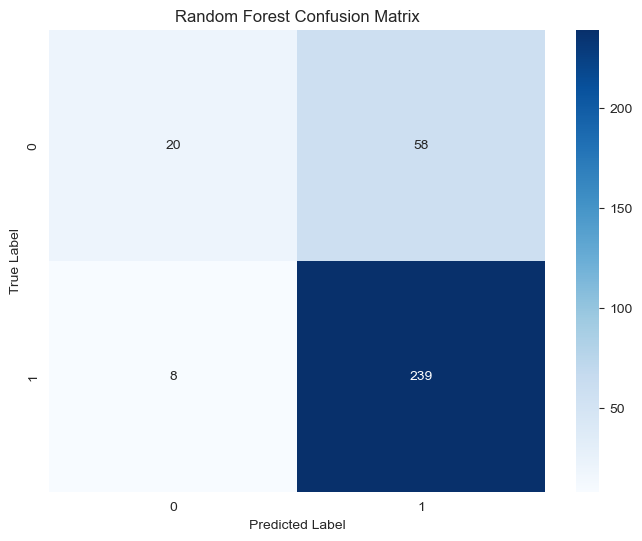

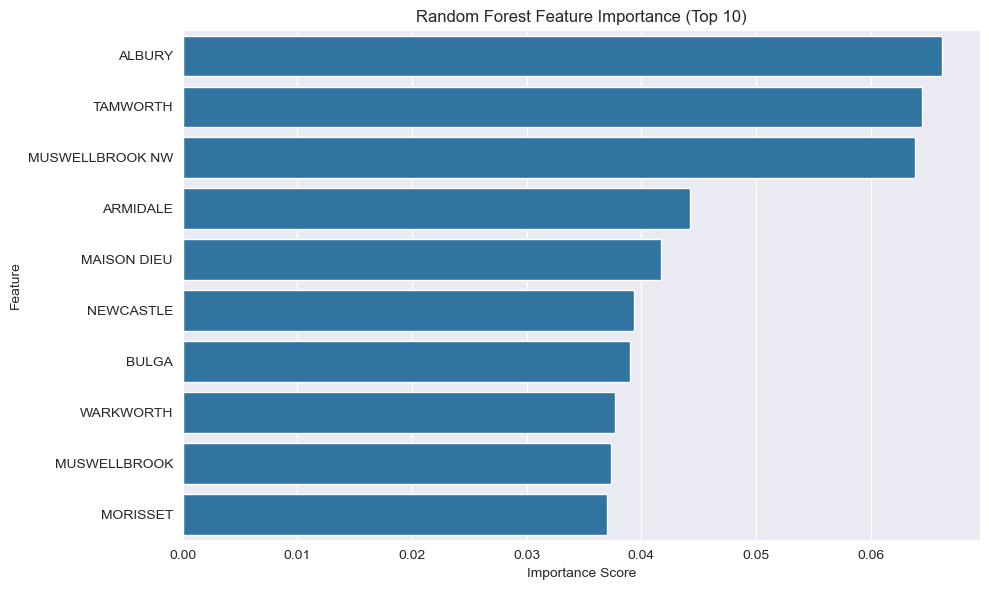

In [7]:
print("\n开始训练和评估模型...")
models = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val)